¿En qué regiones se paga más los hogares por la electricidad? 
Usamos 
EIA-861 Annual Electric Power Industry Report (released: 10/7/2026)
--> Annual sales to ultimate customers by state and sector

Pregunta	Gráfico
1	¿Cuánto varía el precio entre regiones?	histplot
2	¿Depende de la región?	boxplot precio por región
3	¿Donde la luz es más cara se consume menos?	scatterplot consumo por hogar frente a precio, más test de correlación
4	¿Ha subido el precio desde 2010?	lineplot precio medio por región
5	¿Qué estados han subido más?	heatmap estado × año

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
%pip install openpyxl


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
electricity = pd.read_excel(
    "Data/HS861_2010-.xlsx",
    skiprows=3,   # saltar las 3 filas de cabecera
    header=None,  # no usar ninguna fila como cabecera, les pondre nombre yo
    usecols="A:F", # solo año, estado y el bloque residencial
    names=["year", "state", "revenue_thousand_usd", "sales_mwh", "customers", "price_cents_kwh"],)

electricity.head(30)

,year,state,revenue_thousand_usd,sales_mwh,customers,price_cents_kwh
0,2025,AK,532476,2039337,301478,26.11
1,2025,AL,5358942,33304290,2422981,16.09
2,2025,AR,2476663,19246458,1491030,12.87
3,2025,AZ,6041478,39595028,3203578,15.26
4,2025,CA,26685245,85113825,14371581,31.35
5,2025,CO,3224704,20548681,2601457,15.69
6,2025,CT,3918182,13367238,1581525,29.31
7,2025,DC,545807,2489890,324763,21.92
8,2025,DE,912323,5320069,481801,17.15
9,2025,FL,21518482,141435639,10682970,15.21


Quiero ver que infomacion tengo

In [7]:
electricity.info()
electricity["state"].unique()
#veo que US esta como state eso significa que esta el total veo que washington etsa como estado


<class 'pandas.DataFrame'>
RangeIndex: 832 entries, 0 to 831
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  832 non-null    int64  
 1   state                 832 non-null    str    
 2   revenue_thousand_usd  832 non-null    int64  
 3   sales_mwh             832 non-null    int64  
 4   customers             832 non-null    int64  
 5   price_cents_kwh       832 non-null    float64
dtypes: float64(1), int64(4), str(1)
memory usage: 39.1 KB


<StringArray>
['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'HI', 'IA',
 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS',
 'MT', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA',
 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV', 'WY', 'US']
Length: 52, dtype: str

In [8]:
#voy a quitar el US como estado ponerlo en su unico dataframe
us_total = electricity[electricity["state"] == "US"]
electricity = electricity[electricity["state"] != "US"]

electricity["state"].nunique()

51

In [9]:
electricity.columns
#tengo que crear nuevas columnas para mi analisis

Index(['year', 'state', 'revenue_thousand_usd', 'sales_mwh', 'customers',
       'price_cents_kwh'],
      dtype='str')

In [10]:
# Consumo medio por hogar al año (kWh): ventas en MWh × 1000 ÷ nº de hogares
electricity["kwh_per_household"] = electricity["sales_mwh"] * 1000 / electricity["customers"]

# Factura media mensual por hogar ($): ingresos en miles de $ × 1000 ÷ hogares ÷ 12 meses
electricity["monthly_bill_usd"] = electricity["revenue_thousand_usd"] * 1000 / electricity["customers"] / 12

electricity[["state", "year", "price_cents_kwh", "kwh_per_household", "monthly_bill_usd"]].head()

,state,year,price_cents_kwh,kwh_per_household,monthly_bill_usd
0,AK,2025,26.11,6764.463742,147.184869
1,AL,2025,16.09,13745.171753,184.309534
2,AR,2025,12.87,12908.162814,138.420141
3,AZ,2025,15.26,12359.626642,157.154438
4,CA,2025,31.35,5922.370336,154.733875


In [11]:
#voy a redondear pq hay numeros que no tienen sentido 
electricity["kwh_per_household"] = electricity["kwh_per_household"].round(0)
electricity["monthly_bill_usd"] = electricity["monthly_bill_usd"].round(2)

Uso las 4 regiones oficiales del censo de EE. UU., que son las que usa también la EIA:

In [12]:
northeast = ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"]
midwest   = ["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"]
south     = ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV",
             "AL", "KY", "MS", "TN", "AR", "LA", "OK", "TX"]
west      = ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY",
             "AK", "CA", "HI", "OR", "WA"]

electricity.loc[electricity["state"].isin(northeast), "region"] = "Northeast"
electricity.loc[electricity["state"].isin(midwest),   "region"] = "Midwest"
electricity.loc[electricity["state"].isin(south),     "region"] = "South"
electricity.loc[electricity["state"].isin(west),      "region"] = "West"

In [13]:
electricity.to_csv("data/electricity_clean.csv", index=False)

Ahora Graph 1: ¿hay mucha diferencia de precio entre estados?

In [14]:
elec_2025 = electricity[electricity["year"] == 2025]
elec_2025

,year,state,revenue_thousand_usd,sales_mwh,customers,price_cents_kwh,kwh_per_household,monthly_bill_usd,region
0,2025,AK,532476,2039337,301478,26.11,6764.0,147.18,West
1,2025,AL,5358942,33304290,2422981,16.09,13745.0,184.31,South
2,2025,AR,2476663,19246458,1491030,12.87,12908.0,138.42,South
3,2025,AZ,6041478,39595028,3203578,15.26,12360.0,157.15,West
4,2025,CA,26685245,85113825,14371581,31.35,5922.0,154.73,West
5,2025,CO,3224704,20548681,2601457,15.69,7899.0,103.30,West
6,2025,CT,3918182,13367238,1581525,29.31,8452.0,206.46,Northeast
7,2025,DC,545807,2489890,324763,21.92,7667.0,140.05,South
8,2025,DE,912323,5320069,481801,17.15,11042.0,157.80,South
9,2025,FL,21518482,141435639,10682970,15.21,13239.0,167.86,South


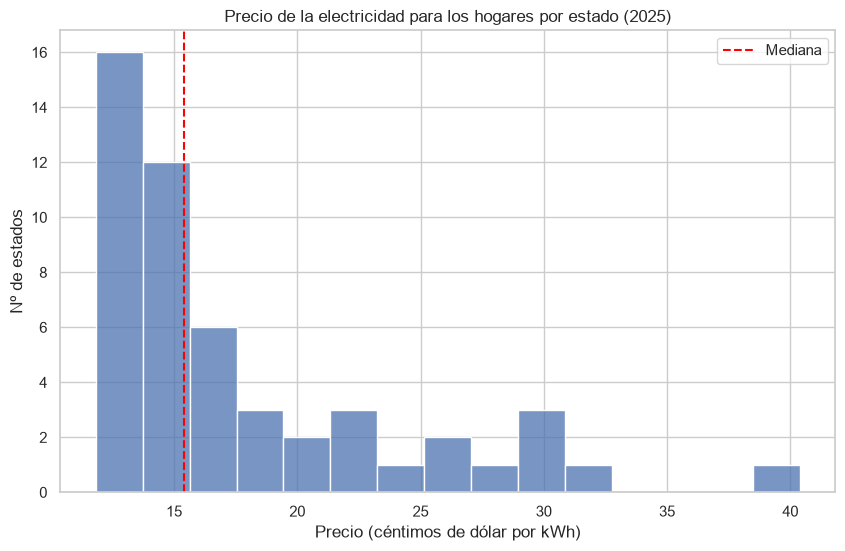

In [15]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(data=elec_2025, x="price_cents_kwh", bins=15)
plt.axvline(elec_2025["price_cents_kwh"].median(), color="red", linestyle="--", label="Mediana")
plt.title("Precio de la electricidad para los hogares por estado (2025)")
plt.xlabel("Precio (céntimos de dólar por kWh)")
plt.ylabel("Nº de estados")
plt.legend()
plt.show()

Graph 2: cuales la region mas cara

In [16]:
order = (
    elec_2025.groupby("region")["price_cents_kwh"]
    .median()
    .sort_values(ascending=False)
    .index)
order

Index(['Northeast', 'Midwest', 'South', 'West'], dtype='str', name='region')

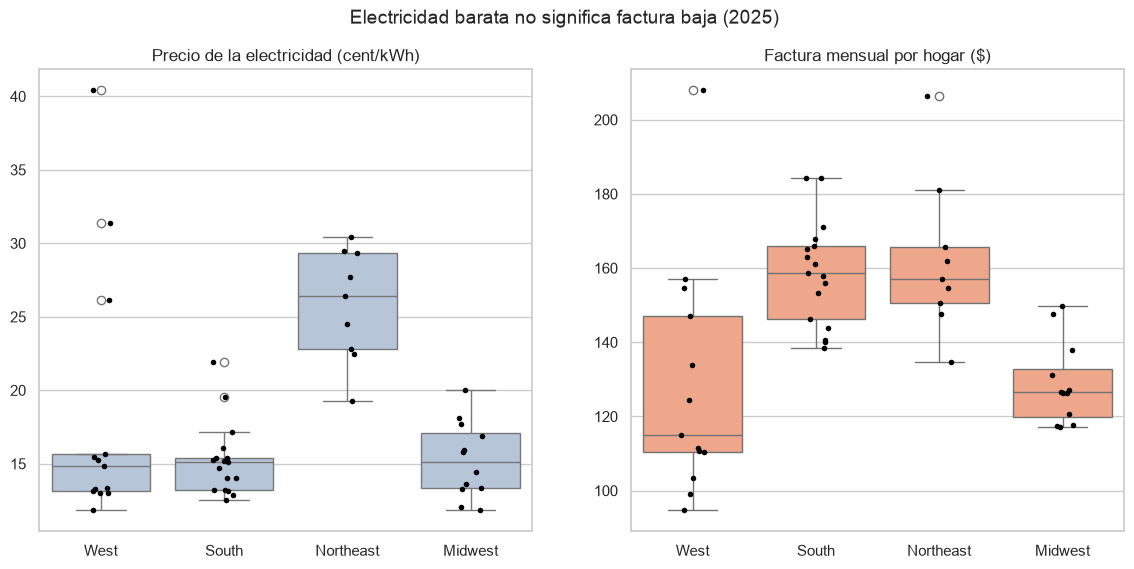

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=elec_2025, x="region", y="price_cents_kwh", ax=axes[0], color="lightsteelblue")
sns.stripplot(data=elec_2025, x="region", y="price_cents_kwh", ax=axes[0], color="black", size=4)
axes[0].set_title("Precio de la electricidad (cent/kWh)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

sns.boxplot(data=elec_2025, x="region", y="monthly_bill_usd", ax=axes[1], color="lightsalmon")
sns.stripplot(data=elec_2025, x="region", y="monthly_bill_usd", ax=axes[1], color="black", size=4)
axes[1].set_title("Factura mensual por hogar ($)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

fig.suptitle("Electricidad barata no significa factura baja (2025)", fontsize=14)

plt.show()

Graph 3: donde la electricidad es mas cara se consume menos?

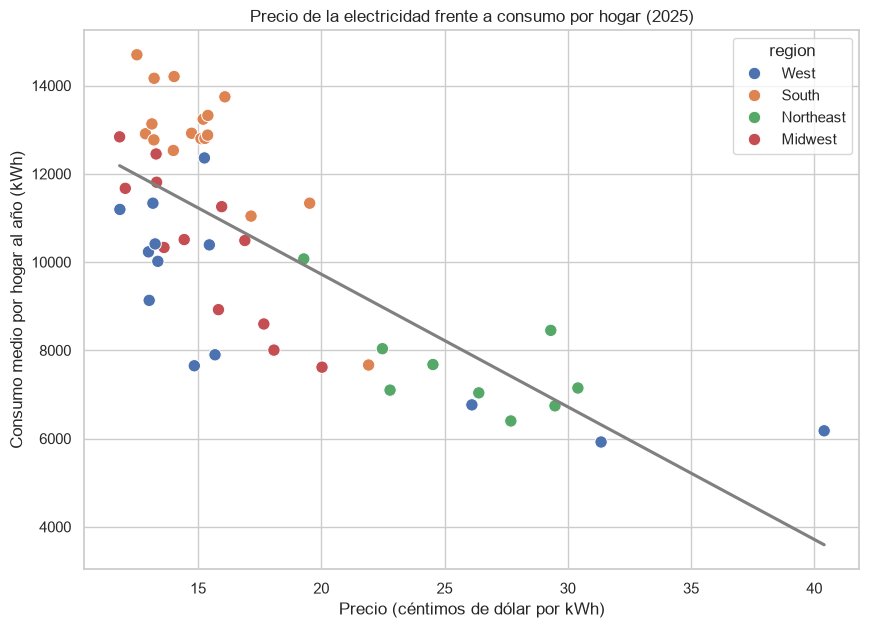

In [18]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=elec_2025, x="price_cents_kwh", y="kwh_per_household",
                hue="region", s=80)
sns.regplot(data=elec_2025, x="price_cents_kwh", y="kwh_per_household",
            scatter=False, color="gray", ci=None)
plt.title("Precio de la electricidad frente a consumo por hogar (2025)")
plt.xlabel("Precio (céntimos de dólar por kWh)")
plt.ylabel("Consumo medio por hogar al año (kWh)")

plt.show()

In [19]:
r = elec_2025["price_cents_kwh"].corr(elec_2025["kwh_per_household"])
r

np.float64(-0.7534562734714149)

In [20]:
elec_2025.kwh_per_household.describe()

count       51.000000
mean     10368.372549
std       2514.309758
min       5922.000000
25%       7952.000000
50%      10489.000000
75%      12783.500000
max      14698.000000
Name: kwh_per_household, dtype: float64

graph 4: ha subido el precio desde 2010?

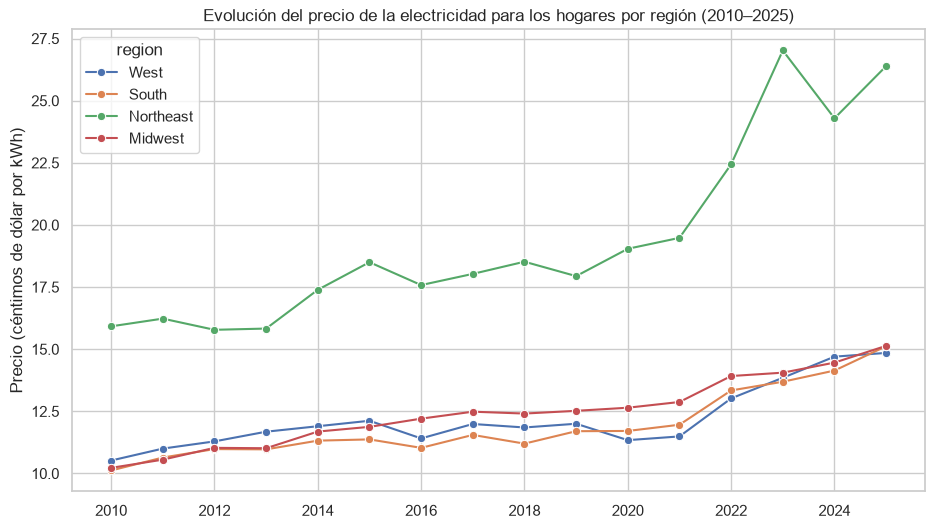

In [21]:
plt.figure(figsize=(11, 6))
sns.lineplot(data=electricity, x="year", y="price_cents_kwh", hue="region",
             estimator="median", errorbar=None, marker="o")

plt.title("Evolución del precio de la electricidad para los hogares por región (2010–2025)")
plt.xlabel("")
plt.ylabel("Precio (céntimos de dólar por kWh)")

plt.show()

In [22]:
corr = elec_2025[["price_cents_kwh", "kwh_per_household", "monthly_bill_usd"]].corr().round(2)
corr

,price_cents_kwh,kwh_per_household,monthly_bill_usd
price_cents_kwh,1.00,-0.75,0.56
kwh_per_household,-0.75,1.00,0.09
monthly_bill_usd,0.56,0.09,1.00


In [23]:
elec_2025.sort_values("price_cents_kwh", ascending=False)

,year,state,revenue_thousand_usd,sales_mwh,customers,price_cents_kwh,kwh_per_household,monthly_bill_usd,region
11,2025,HI,1119786,2772081,448869,40.40,6176.0,207.89,West
4,2025,CA,26685245,85113825,14371581,31.35,5922.0,154.73,West
19,2025,MA,6343159,20861216,2919186,30.41,7146.0,181.08,Northeast
39,2025,RI,923946,3134178,464880,29.48,6742.0,165.62,Northeast
6,2025,CT,3918182,13367238,1581525,29.31,8452.0,206.46,Northeast
21,2025,ME,1327670,4793977,749232,27.69,6399.0,147.67,Northeast
34,2025,NY,13857839,52505369,7462709,26.39,7036.0,154.75,Northeast
0,2025,AK,532476,2039337,301478,26.11,6764.0,147.18,West
30,2025,NH,1239374,5053198,658104,24.53,7678.0,156.94,Northeast
46,2025,VT,507774,2228407,313956,22.79,7098.0,134.78,Northeast


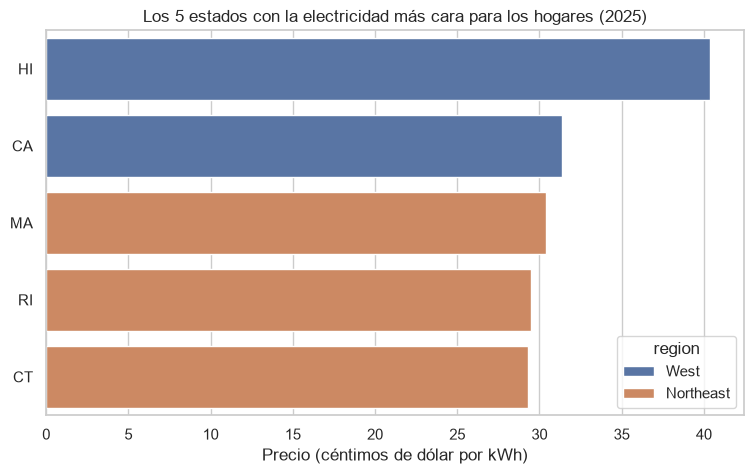

In [24]:
top5 = elec_2025.sort_values("price_cents_kwh", ascending=False).head(5)

plt.figure(figsize=(9, 5))
sns.barplot(data=top5, x="price_cents_kwh", y="state", hue="region")
plt.title("Los 5 estados con la electricidad más cara para los hogares (2025)")
plt.xlabel("Precio (céntimos de dólar por kWh)")
plt.ylabel("")

plt.show()

Ahora quiero saber si influye cómo produce electricidad cada estado en lo que pagan sus familias

In [25]:
generation = pd.read_excel("data/annual_generation_state.xlsx", header=1)
generation.columns = ["year", "state", "producer", "source", "mwh"]
generation.head()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,year,state,producer,source,mwh
0,1990,AK,Total Electric Power Industry,Total,5599506.0
1,1990,AK,Total Electric Power Industry,Coal,510573.0
2,1990,AK,Total Electric Power Industry,Hydroelectric Conventional,974521.0
3,1990,AK,Total Electric Power Industry,Natural Gas,3466261.0
4,1990,AK,Total Electric Power Industry,Petroleum,497116.0


Nos quedamos solo con 2025 y con el total de productores para tener una sola cifra por estado y fuente, comparable con los precios de 2025 que ya tienes, sin contar la misma electricidad varias veces. Quitamos “US-Total” porque es la suma del país y no un estado, igual que hicimos con “US” en la otra tabla.

In [ ]:
gen_2025 = generation[(generation["year"] == 2025)
    & (generation["producer"] == "Total Electric Power Industry")
    & (generation["state"] != "US-Total")
]

gen_2025["state"].nunique()
gen_2025["source"].unique()
#vamos a agruparlas en 5, porque 14 son demasiadas para un gráfico:

<StringArray>
[                         'Total',                           'Coal',
     'Hydroelectric Conventional',                    'Natural Gas',
                          'Other',                      'Petroleum',
 'Solar Thermal and Photovoltaic',                  'Other Biomass',
                           'Wind',    'Wood and Wood Derived Fuels',
                        'Nuclear',                    'Other Gases',
                 'Pumped Storage',                     'Geothermal']
Length: 14, dtype: str

In [30]:
gen_wide = gen_2025.pivot_table(index="state", columns="source", values="mwh", aggfunc="sum").fillna(0)
gen_wide.head()

source,Coal,Geothermal,Hydroelectric Conventional,Natural Gas,Nuclear,Other,Other Biomass,Other Gases,Petroleum,Pumped Storage,Solar Thermal and Photovoltaic,Total,Wind,Wood and Wood Derived Fuels
state,,,,,,,,,,,,,,
AK,789644.0,0.0,1772607.0,3769651.0,0.0,-7753.0,40473.0,0.0,1041275.0,0.0,8024.0,7537732.0,123812.0,0.0
AL,21661512.0,0.0,8582856.0,65595154.0,42672668.0,6526.0,24319.0,0.0,10445.0,0.0,1323287.0,142994795.0,0.0,3118028.0
AR,20379592.0,0.0,3920304.0,23227485.0,15193050.0,5792.0,29844.0,0.0,44355.0,105393.0,4737101.0,68607241.0,176213.0,788112.0
AZ,9218820.0,0.0,4782575.0,52670485.0,31321808.0,-512808.0,21236.0,0.0,40820.0,71393.0,15504450.0,116470876.0,3149874.0,202223.0
CA,234247.0,10898667.0,28146480.0,74287239.0,17558394.0,-1694573.0,2243633.0,1113794.0,54307.0,219025.0,54887978.0,205105814.0,15094716.0,2061906.0


Ahora hay que hacer los porentakjes pq el total amoutn es absoluto no relativo 


In [31]:
renewables = ["Hydroelectric Conventional", "Wind", "Solar Thermal and Photovoltaic",
              "Geothermal", "Wood and Wood Derived Fuels", "Other Biomass"]

mix = pd.DataFrame({
    "pct_coal":       gen_wide["Coal"] / gen_wide["Total"] * 100,
    "pct_gas":        gen_wide["Natural Gas"] / gen_wide["Total"] * 100,
    "pct_nuclear":    gen_wide["Nuclear"] / gen_wide["Total"] * 100,
    "pct_petroleum":  gen_wide["Petroleum"] / gen_wide["Total"] * 100,
    "pct_renewables": gen_wide[renewables].sum(axis=1) / gen_wide["Total"] * 100,
}).round(1).reset_index()

mix.head()

,state,pct_coal,pct_gas,pct_nuclear,pct_petroleum,pct_renewables
0,AK,10.5,50.0,0.0,13.8,25.8
1,AL,15.1,45.9,29.8,0.0,9.1
2,AR,29.7,33.9,22.1,0.1,14.1
3,AZ,7.9,45.2,26.9,0.0,20.3
4,CA,0.1,36.2,8.6,0.0,55.3


ahora busco dos tablas con una fila por estado: elec_2025 (precio, factura, región) y mix (los %). merge(on="state") las pega usando el estado como columna común,

In [35]:
price_mix = elec_2025.merge(mix, on="state")

cols = ["pct_coal", "pct_gas", "pct_nuclear", "pct_petroleum", "pct_renewables"]

price_mix[cols].corrwith(price_mix["price_cents_kwh"]).round(2).sort_values()


pct_coal         -0.47
pct_renewables   -0.08
pct_nuclear       0.03
pct_gas           0.22
pct_petroleum     0.56
dtype: float64

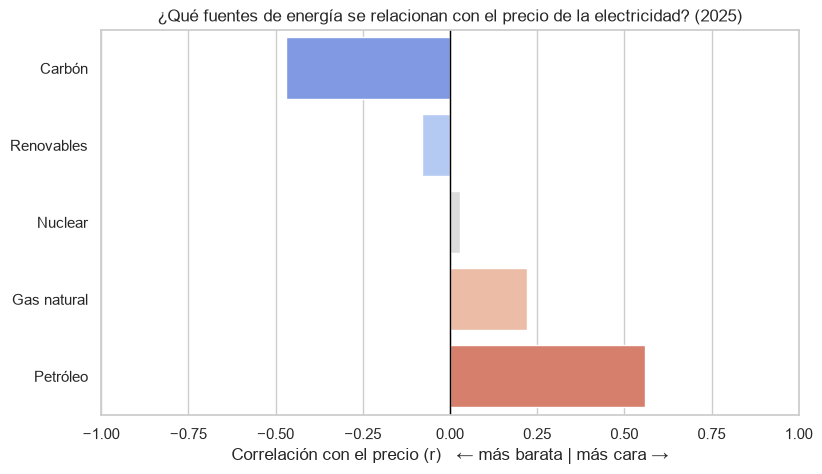

In [37]:
corr_mix = price_mix[cols].corrwith(price_mix["price_cents_kwh"]).round(2).sort_values()

names = {"pct_coal": "Carbón", "pct_gas": "Gas natural", "pct_nuclear": "Nuclear",
         "pct_petroleum": "Petróleo", "pct_renewables": "Renovables"}
corr_df = corr_mix.rename(index=names).reset_index()
corr_df.columns = ["fuente", "r"]

plt.figure(figsize=(9, 5))
sns.barplot(data=corr_df, x="r", y="fuente", hue="fuente", palette="coolwarm", legend=False)
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1, 1)
plt.title("¿Qué fuentes de energía se relacionan con el precio de la electricidad? (2025)")
plt.xlabel("Correlación con el precio (r)   ← más barata | más cara →")
plt.ylabel("")

plt.show()